# ScreenWise — Exploratory Data Analysis

Dataset: `ScreenTime vs MentalWellness.csv` (400 rows, loaded from `data/`).

This notebook inspects the raw data, documents cleaning decisions, explores relationships between screen time / lifestyle variables and the wellness index, and verifies the target-construction methodology used in `ml/preprocess.py`. It does not build the deployed model — that happens in `ml/train.py`.

In [1]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

df = pd.read_csv('../data/ScreenTime vs MentalWellness.csv')
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
df.shape

(400, 15)

## 1. Dataset overview

In [2]:
df.head()

,user_id,age,gender,occupation,work_mode,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week,mental_wellness_index_0_100
0,U0001,33,Female,Employed,Remote,10.79,5.44,5.35,6.63,1,9.3,44.7,127,0.7,9.3
1,U0002,28,Female,Employed,In-person,7.40,0.37,7.03,8.05,3,5.7,78.0,74,2.1,56.2
2,U0003,35,Female,Employed,Hybrid,9.78,1.09,8.69,6.48,1,9.1,51.8,67,8.0,3.6
3,U0004,42,Male,Employed,Hybrid,11.13,0.56,10.57,6.89,1,10.0,37.0,0,5.7,0.0
4,U0005,28,Male,Student,Remote,13.22,4.09,9.13,5.79,1,10.0,38.5,143,10.1,0.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   user_id                      400 non-null    object 
 1   age                          400 non-null    int64  
 2   gender                       400 non-null    object 
 3   occupation                   400 non-null    object 
 4   work_mode                    400 non-null    object 
 5   screen_time_hours            400 non-null    float64
 6   work_screen_hours            400 non-null    float64
 7   leisure_screen_hours         400 non-null    float64
 8   sleep_hours                  400 non-null    float64
 9   sleep_quality_1_5            400 non-null    int64  
 10  stress_level_0_10            400 non-null    float64
 11  productivity_0_100           400 non-null    float64
 12  exercise_minutes_per_week    400 non-null    int64  
 13  social_hours_per_wee

## 2. Missing values & duplicates

In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Missing values per column:
user_id                        0
age                            0
gender                         0
occupation                     0
work_mode                      0
screen_time_hours              0
work_screen_hours              0
leisure_screen_hours           0
sleep_hours                    0
sleep_quality_1_5              0
stress_level_0_10              0
productivity_0_100             0
exercise_minutes_per_week      0
social_hours_per_week          0
mental_wellness_index_0_100    0
dtype: int64

Duplicate rows: 0


## 3. Descriptive statistics

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
user_id,400,400,U0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,400.0,NaN,NaN,NaN,29.7775,7.46608,16.0,24.0,30.0,35.0,60.0
gender,400,3,Female,222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,400,5,Employed,207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_mode,400,3,Remote,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
screen_time_hours,400.0,NaN,NaN,NaN,9.0249,2.491058,1.0,7.3725,9.09,10.495,19.17
work_screen_hours,400.0,NaN,NaN,NaN,2.183075,1.931321,0.11,0.695,1.455,3.0125,12.04
leisure_screen_hours,400.0,NaN,NaN,NaN,6.841825,2.220896,0.89,5.46,6.7,8.4175,13.35
sleep_hours,400.0,NaN,NaN,NaN,7.013175,0.852421,4.64,6.3975,7.03,7.64,9.74
sleep_quality_1_5,400.0,NaN,NaN,NaN,1.3975,0.652348,1.0,1.0,1.0,2.0,4.0


## 4. Distributions — numerical features

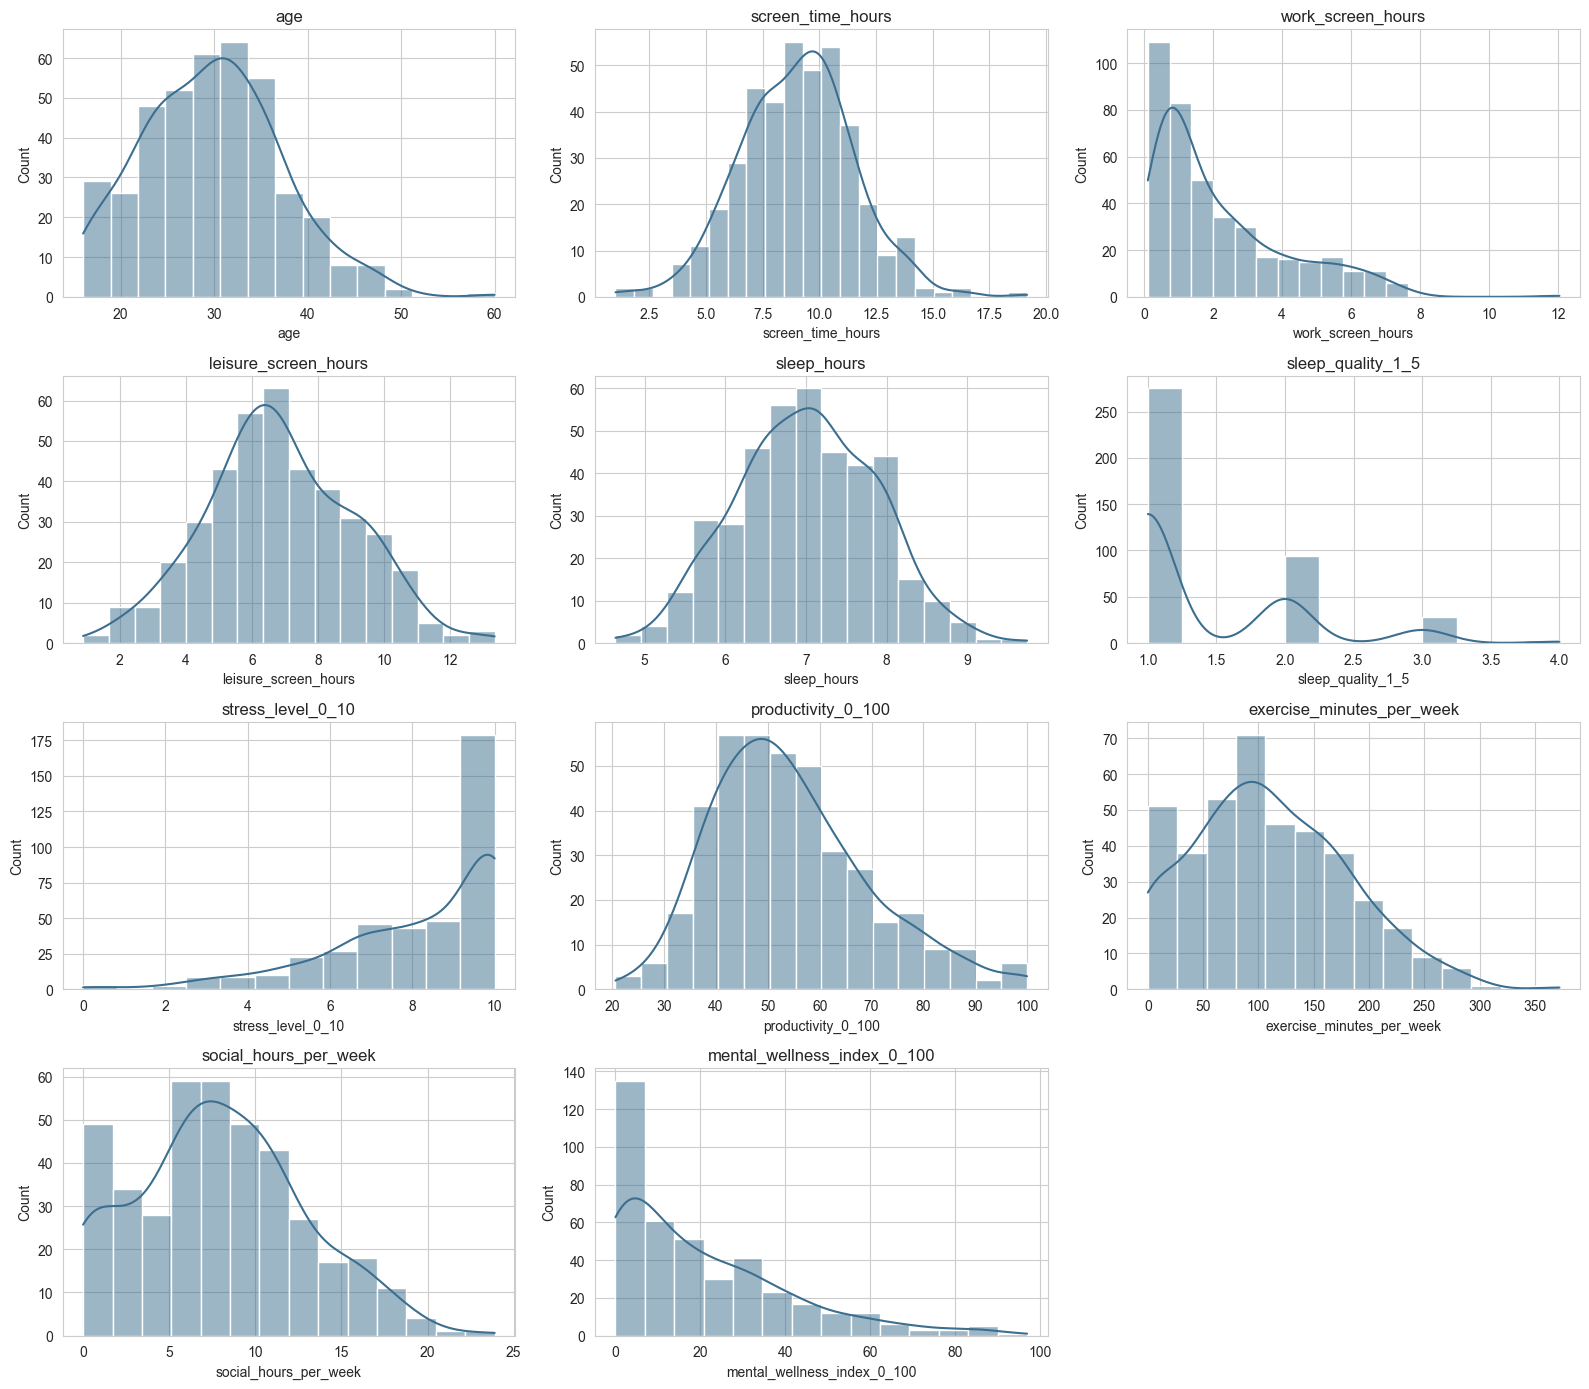

In [6]:
numeric_cols = ['age', 'screen_time_hours', 'work_screen_hours', 'leisure_screen_hours',
                'sleep_hours', 'sleep_quality_1_5', 'stress_level_0_10', 'productivity_0_100',
                'exercise_minutes_per_week', 'social_hours_per_week', 'mental_wellness_index_0_100']
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='#3b6e8f')
    ax.set_title(col)
for ax in axes.flat[len(numeric_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Categorical feature counts

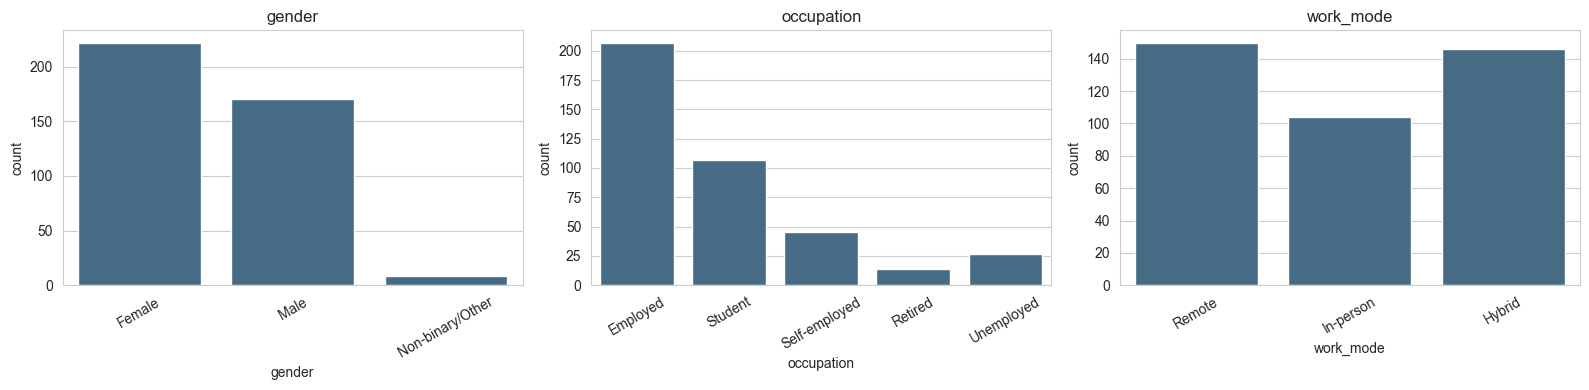

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['gender', 'occupation', 'work_mode']):
    sns.countplot(data=df, x=col, ax=ax, color='#3b6e8f')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 6. Correlation heatmap

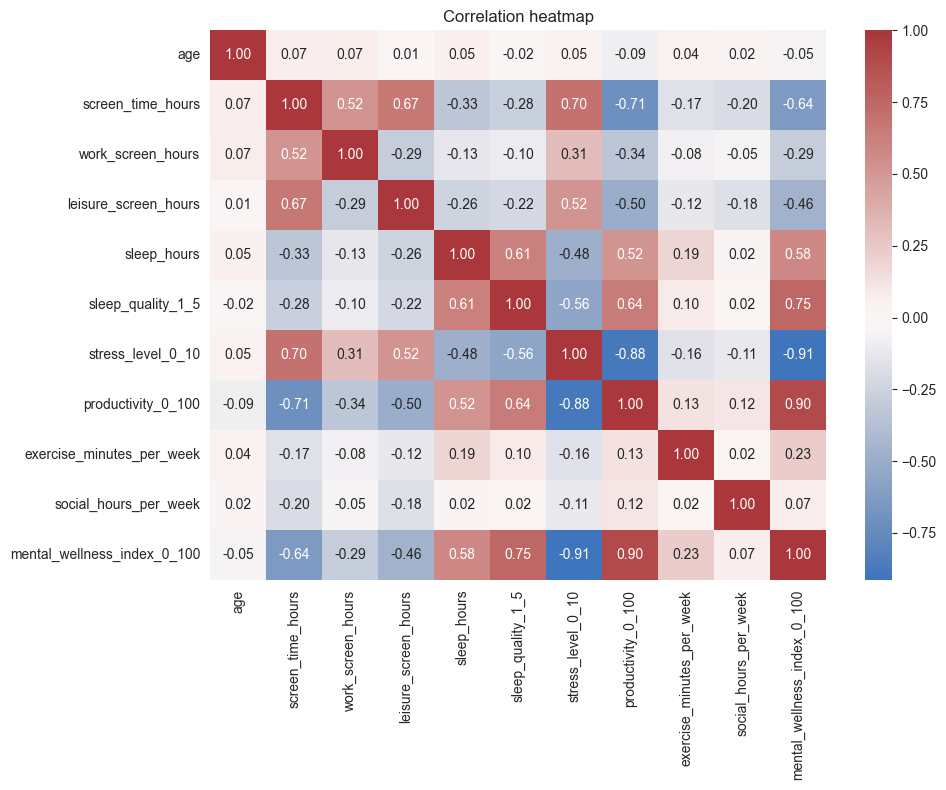

In [8]:
plt.figure(figsize=(10, 8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Correlation heatmap')
plt.tight_layout()
plt.show()

## 7. Verifying target construction

`mental_wellness_index_0_100` correlates very strongly with `stress_level_0_10` (negative) and `productivity_0_100` (positive), and moderately with `sleep_quality_1_5`. We check whether it matches the brief's formula:

`score = normalized_productivity + normalized_sleep_quality + inverse_normalized_stress`, rescaled to 0-100.

Correlation between reconstructed formula and actual mental_wellness_index_0_100: 0.9572


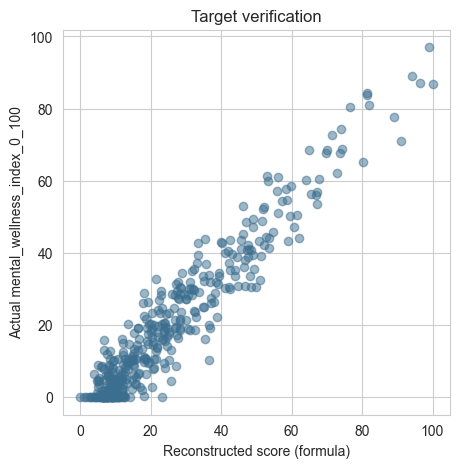

In [9]:
norm_prod = df['productivity_0_100'] / 100
norm_sleepq = (df['sleep_quality_1_5'] - 1) / (df['sleep_quality_1_5'].max() - 1)
inv_stress = (10 - df['stress_level_0_10']) / 10

combo = norm_prod + norm_sleepq + inv_stress
combo_scaled = (combo - combo.min()) / (combo.max() - combo.min()) * 100

print('Correlation between reconstructed formula and actual mental_wellness_index_0_100:',
      round(np.corrcoef(combo_scaled, df['mental_wellness_index_0_100'])[0, 1], 4))

plt.figure(figsize=(5, 5))
plt.scatter(combo_scaled, df['mental_wellness_index_0_100'], alpha=0.5, color='#3b6e8f')
plt.xlabel('Reconstructed score (formula)')
plt.ylabel('Actual mental_wellness_index_0_100')
plt.title('Target verification')
plt.show()

**Conclusion:** the correlation is ~0.96, confirming `mental_wellness_index_0_100` was already built from productivity, sleep quality, and (inverse) stress. `ml/preprocess.py` therefore reuses this column directly as the wellness score rather than re-deriving an approximation, and excludes `productivity_0_100`, `sleep_quality_1_5`, and `stress_level_0_10` from the model's input features to prevent data leakage.

## 8. Target category distribution (tercile thresholds)

Bin edges: [ 0.   6.6 25.1 97. ]
wellness_category
Low         134
Moderate    133
High        133
Name: count, dtype: int64


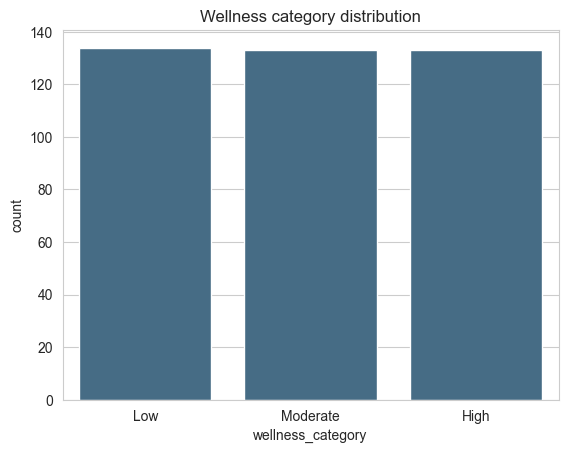

In [10]:
labels = ['Low', 'Moderate', 'High']
df['wellness_category'], edges = pd.qcut(df['mental_wellness_index_0_100'], q=3, labels=labels, retbins=True, duplicates='drop')
print('Bin edges:', edges)
print(df['wellness_category'].value_counts())
sns.countplot(data=df, x='wellness_category', order=labels, color='#3b6e8f')
plt.title('Wellness category distribution')
plt.show()

## 9. Screen time vs. wellness score

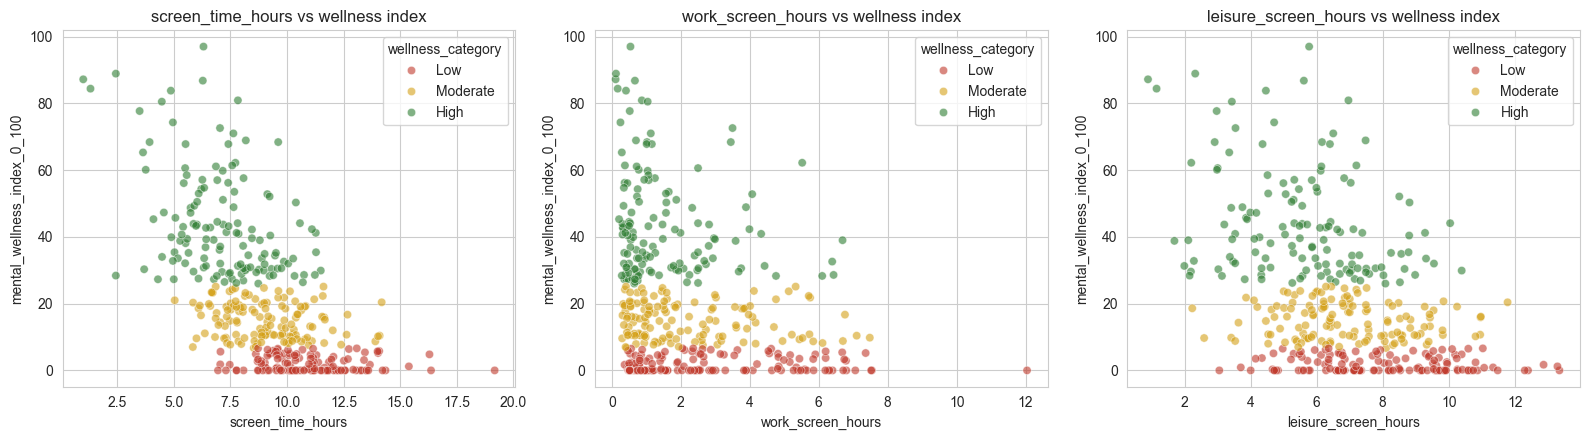

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['screen_time_hours', 'work_screen_hours', 'leisure_screen_hours']):
    sns.scatterplot(data=df, x=col, y='mental_wellness_index_0_100', hue='wellness_category',
                     hue_order=labels, ax=ax, palette=['#c0392b', '#d4a017', '#2e7d32'], alpha=0.6)
    ax.set_title(f'{col} vs wellness index')
plt.tight_layout()
plt.show()

## 10. Observations

- Higher total and leisure screen time is associated with a lower wellness index; this is a **correlation observed in this sample**, not a demonstrated causal effect — reverse causation (lower wellness leading to more screen use) and confounding lifestyle factors are equally plausible explanations.
- Sleep hours and sleep quality trend positively with wellness; stress trends strongly negatively (by construction, since stress was one of the indicators used to build the index).
- The dataset is small (400 rows after cleaning) and cross-sectional (one row per user, no time dimension), so findings should be read as descriptive patterns in this sample rather than generalizable claims.
- No missing values or duplicate rows were found; the only cleaning step required was dropping the trailing empty `Unnamed: 15` column and the non-predictive `user_id` identifier.